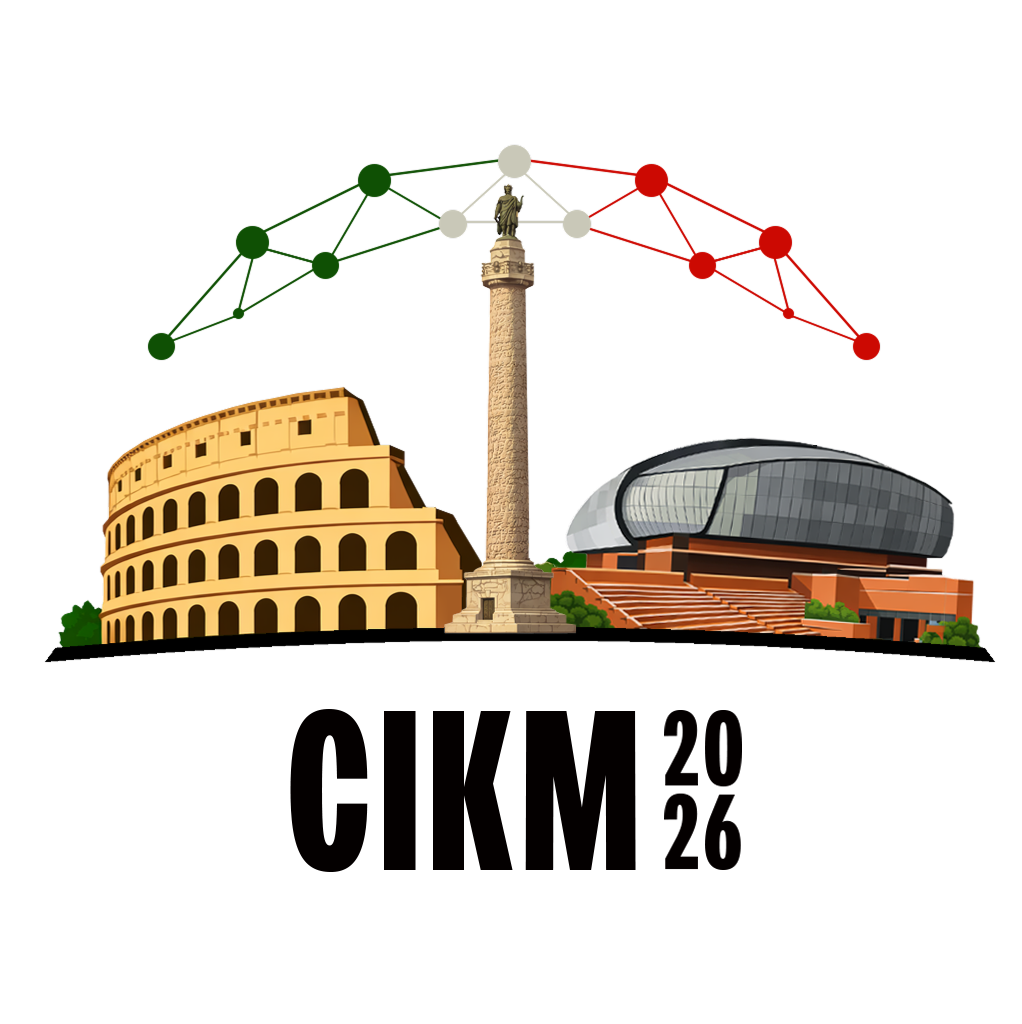

# M3: Measure how typos affect search

Beyond Benchmarks: Robustness for Real-World Information Systems

Bum Jun Kim, The University of Tokyo, CIKM 2026

7 November 2026 · [San Pietro in Vincoli Campus, Sapienza University of Rome](https://cikm2026.diag.uniroma1.it/venues/) · Rome, Italy

Learning objective: Test all 300 SciFact queries. Measure the average loss, inspect individual failures, and compare different edit counts.

M1 shows selected examples. This module shows how often the outcomes occur. Run it on its own with Restart Kernel → Run All.


In [1]:
# Load the libraries, SciFact data, and saved model results.
from pathlib import Path
import sys
ROOT = next(p / "resources" for p in [Path.cwd(), *Path.cwd().parents] if (p / "resources" / "tutorial_utils").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
%matplotlib inline
from tutorial_utils import load_tutorial_context
from tutorial_utils import measurement as meas

from tutorial_utils.presentation import install_plain_display
install_plain_display()

MODE = "cached"
ctx = load_tutorial_context(mode=MODE, seed=42)
print(ctx.banner())

MODE=cached | SciFact | 5183 documents | 300 test queries
BM25 / MiniLM dense exact retrieval → MiniLM cross-encoder (20 candidates)


## How to compare the systems

BM25, Dense, and Dense → reranker use the same papers and qrels. Model weights stay fixed. [M1's appendix](M1_Observe_Failures.ipynb#m1-ndcg-appendix) explains the metrics.

nDCG@10 rewards finding relevant papers early in the first ten results. It ranges from 0 to 1; higher is better.

For each query, calculate ΔnDCG@10 = typo score − original score. Then average these changes. Negative means an average loss; positive means an average gain. Zero means equal averages, even if individual scores or returned papers changed.


## Experiment Settings

`severity` is the maximum character edits per query: 0, 1, 2, or 3. The default is 1. Zero leaves every query unchanged.

After changing it, select the code cell below and use Run All Below. All comparisons use nDCG@10.


In [2]:
# Set the maximum number of character edits per query.
severity = 1  # Maximum edits: 0 (no edits), 1, 2, or 3.

In [3]:
# Prepare search results for the original queries and their typo versions.
results = meas.prepare_questions(ctx, severity=severity)

## Which system works best after typos?

The columns answer two questions:

- `After typos`: which system has the highest final score?
- `Mean ΔnDCG@10`: which system loses the fewest points?

The answers can differ. A change of −0.02 means a loss of 0.02 score points, not a 2% relative loss.


In [4]:
# Compare each system's search quality before and after typos.
meas.show_comparison(results)

System,Before typos,After typos,Mean ΔnDCG@10
BM25,0.6617,0.6461,-0.0156
Dense,0.6451,0.6220,-0.0231
Dense → reranker,0.6865,0.6633,-0.0232


<a id="m3-selected-examples"></a>
## Which failures does the average hide?

The bars count Dense queries whose scores fell, stayed equal, or rose. Gains can cancel out losses in the average. Many unchanged scores can also hide a few large failures.

The Selected severity-1 cases table shows M1's three examples. It always uses one edit, even if you choose another setting for the bars. We chose the cases after scoring the test set to show a loss, no change, and a gain. The bars show how often those outcomes occur.

The table reads `results["systems"]["Dense"][1]["scores"]`. The source rankings are `dense_s0` and `dense_s1` in `resources/assets/caches/runs.json`. The relevance labels are in `resources/data/scifact/qrels/test.tsv`.


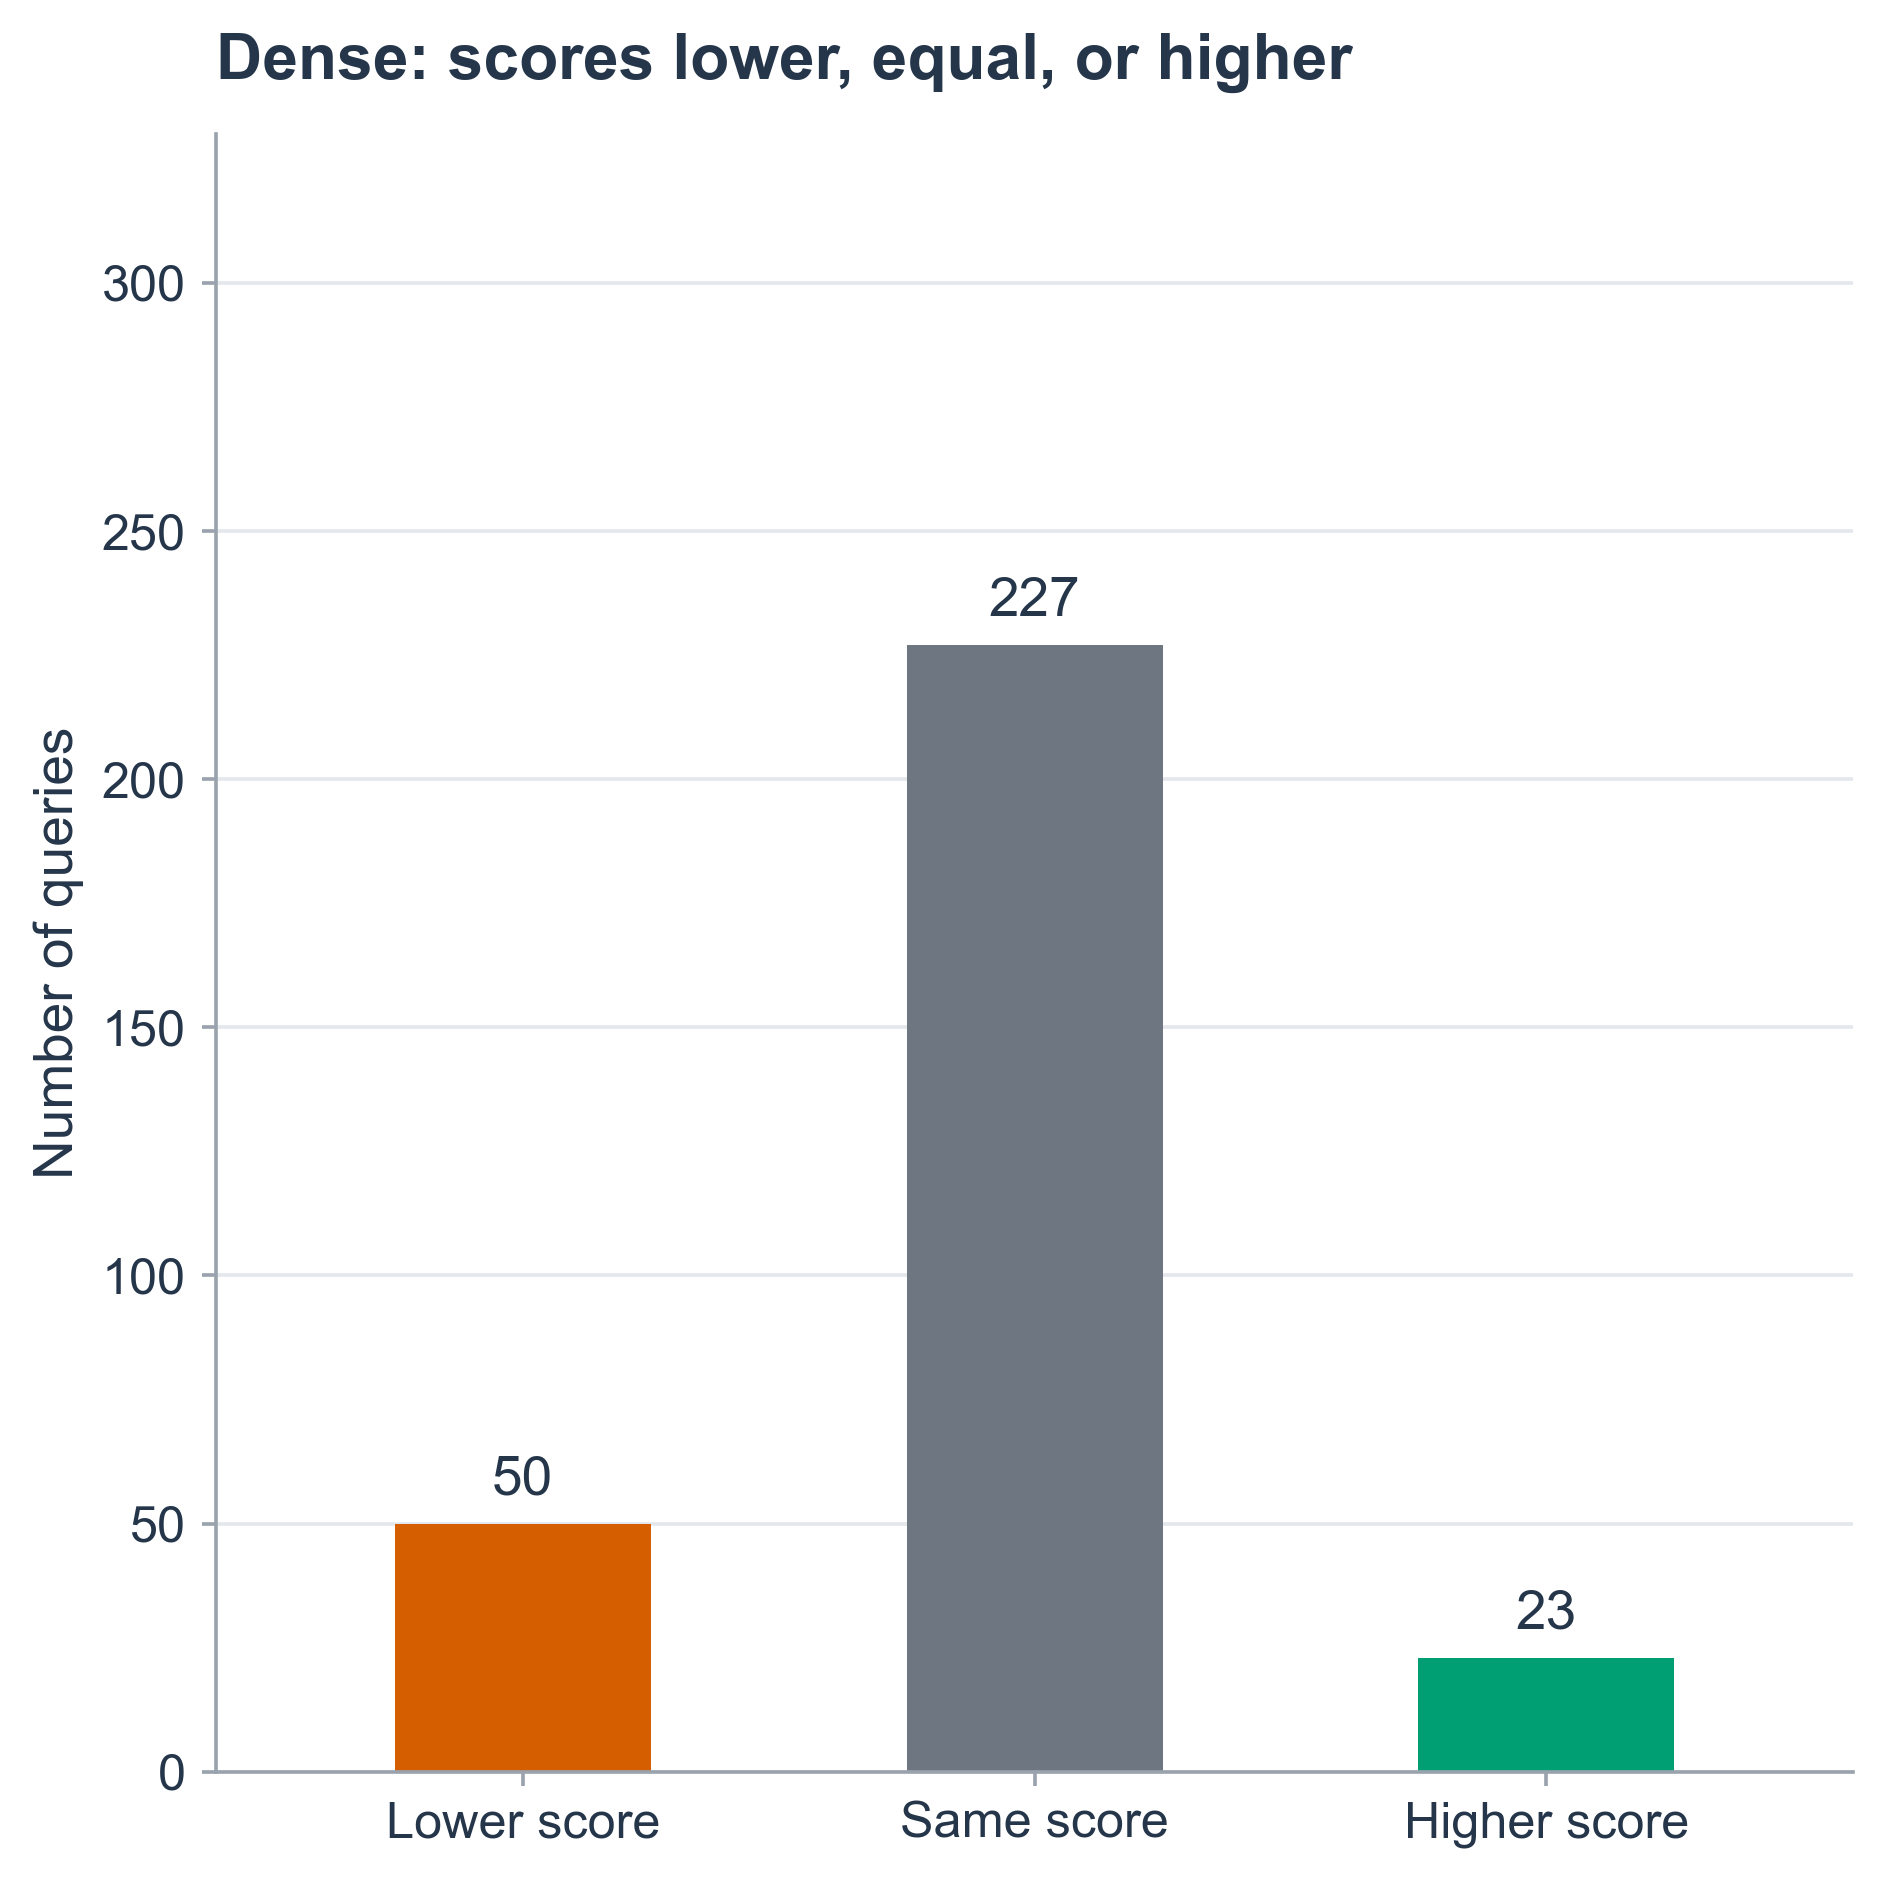

Dense: 50 lower, 227 same, and 23 higher scores. Queries with lower scores lose 0.2503 on average. Gains on other queries cancel out part of this loss in the average. Queries with unchanged scores also count in the average. Across all 300 queries, mean nDCG@10 goes from 0.6451 to 0.6220 (Δ-0.0231).

Query ID,Example,Original nDCG@10,One-edit nDCG@10,ΔnDCG@10
1303,Tirasemtiv,1.0000,0.0000,-1.0000
1012,Radioiodine,1.0000,1.0000,0.0000
628,HTLV-1,0.4307,1.0000,0.5693


In [5]:
# Count queries with lower, unchanged, or higher scores after typos.
meas.show_query_outcomes(ctx, results)

## What happens with more edits?

The graph and table always show maximum edit counts 0, 1, 2, and 3. Zero leaves every query unchanged. Higher points mean less loss or more gain from the original score. The shaded column marks your chosen setting.

Some queries receive fewer edits than requested because they have too few eligible words. At severity 2, 299 of 300 queries receive two edits. At severity 3, 278 receive three. These counts come from `results["audit"]`.

More edits can lower the average without making every query worse.


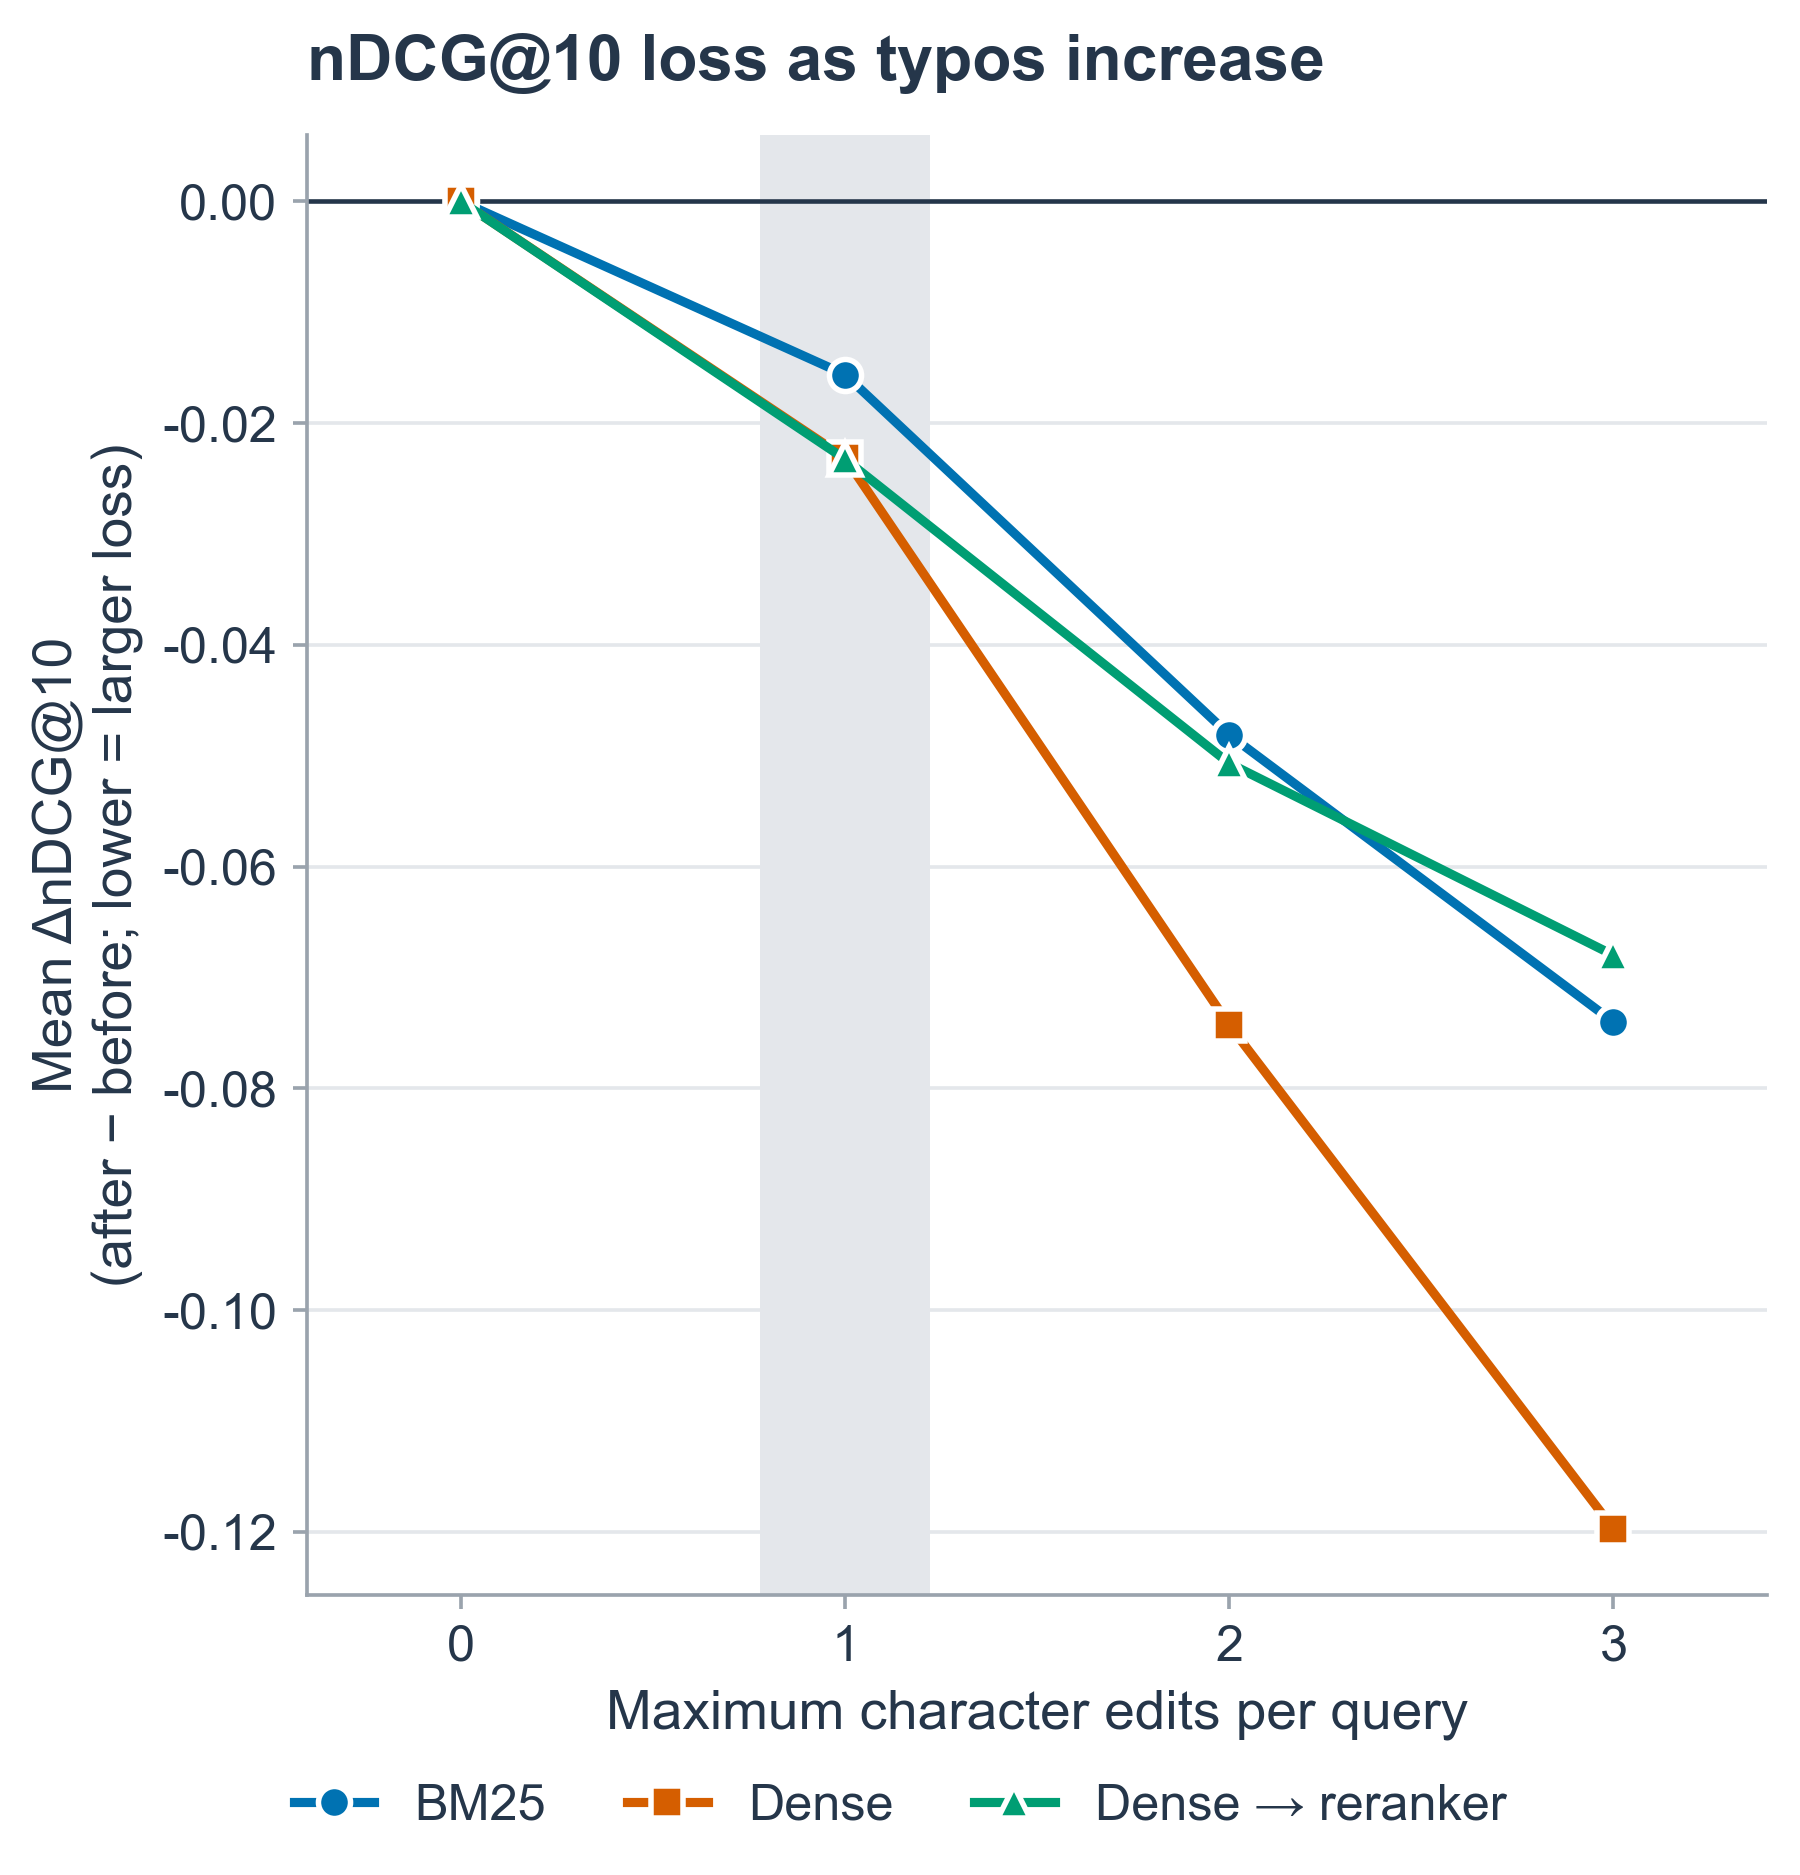

Maximum edits,BM25,Dense,Dense → reranker,Observed leader(s)
0,0.0000,0.0000,0.0000,"BM25, Dense, Dense → reranker"
1,-0.0156,-0.0231,-0.0232,BM25
2,-0.0481,-0.0743,-0.0507,BM25
3,-0.0740,-0.1197,-0.0680,Dense → reranker


In [6]:
# Compare search quality across all four typo levels.
meas.show_severity_experiment(results)

## Lesson Summary

Report the score after typos and the change from the original score. Also check individual failures and actual edit counts. The system with the highest final score may have a larger average loss or more complete failures.


Next: [M4: Improve retrieval robustness](M4_Improve_Robustness.ipynb).

### Sources to read

- Järvelin & Kekäläinen (ACM TOIS 2002), [Cumulated gain-based evaluation of IR techniques](https://doi.org/10.1145/582415.582418): scoring relevant papers by their ranks.
- Sidiropoulos & Kanoulas (SIGIR 2022), [Analysing the Robustness of Dual Encoders for Dense Retrieval Against Misspellings](https://doi.org/10.1145/3477495.3531818): testing dense search on misspelled queries.
